# 5 — How do rookies evolve? The Jack McVeigh build

**In brief**
- **Question:** Where do lottery picks start, how much do they stand out from their peers in style and size, and what does it say about the careers that follow?
- **Answer (Stages 1, 1.1 and 2, 24 November 2026):** see the dated findings under each stage.
- **Decisions** ([decision log](../../docs/DECISIONS.md)): D49–D70.
- **Dated:** Stage 1 uses the 2026-27 season up to 22 November 2026 (day 33 after opening night).

**How it works**
- **Pools.** A pool is everyone who played in one setting: a year's summer leagues (all combined, D56), a preseason, or a regular season cut at a check-in (D63: the same day after opening night as today's snapshot, the All-Star break, and season's end).
- **Style** is the box score plus shot diet: the 15 measures of the play-style groups in segment 2 (D49 revised, D57). **Size** is listed height and weight, from the sources in D58's order.
- **The map** places each player twice on a 1 (guard) to 5 (centre) scale: once from his body, once from how he plays. Both models are the project's position models (D5), fitted on earlier regular seasons only.
- **Uniqueness** is how far a player stands out from his pool on style and size together (Mahalanobis distance, as a percentile within the pool; D50, D57). Twins are allowed: several players can be unusual in the same way.
- **Small samples are used as played** (D59): there is no minimum minutes yet, so a player with very few minutes can look extreme. Minutes are shown next to every score.
- **No assumptions** (D61, D62): an action that did not happen counts as zero; data that does not exist is dropped, never estimated.
- Points per game is not used anywhere in this notebook.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("run this notebook from inside the project folder")
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from nba_api.stats.endpoints import drafthistory, leaguegamelog
from unicorn import rookies as R
from unicorn.gamelogs import all_star_breaks, load_game_logs
from unicorn.plotting import FIG_DIR
from unicorn.raw import fetch

pd.set_option("display.width", 200, "display.max_colwidth", 120)
SNAPSHOT = pd.Timestamp("2026-11-22")   # the last complete night when Stage 1 was written (D63)

draft = fetch(drafthistory.DraftHistory)["DraftHistory"].assign(SEASON=lambda d: d["SEASON"].astype(int))
def lottery(year):
    d = draft[(draft["SEASON"] == year) & (draft["OVERALL_PICK"] <= 14)].sort_values("OVERALL_PICK")
    return dict(zip(d["PERSON_ID"].astype(int), d["PLAYER_NAME"]))

def scored(pool, last_train):
    return R.add_uniqueness(R.add_map(pool, last_train))

def pick_table(pools, picks):
    rows = []
    for label, p in pools.items():
        mine = p[p.index.isin(picks)]
        why = R.reasons(p, mine.index)
        rows.append(mine.assign(pool=label, **{"what stands out": why})[
            ["pool", "player_name", "games", "min", "position_body", "position_style", "uniqueness_pctl",
             "uniqueness_style_pctl", "uniqueness_size_pctl", "what stands out"]])
    t = pd.concat(rows)
    t.columns = ["pool", "player", "games", "minutes", "body position", "style position", "uniqueness",
                 "style part", "size part", "what stands out"]
    return t.round(1)

## Stage 1 — This year's lottery picks on the map

The 14 lottery picks of the 2026 draft, in three pools: the 2026 summer leagues (Las Vegas, California and Utah combined), the 2026-27 preseason, and the regular season up to 22 November 2026 (day 33 after opening night).

In [2]:
LOT26 = lottery(2026)
live = fetch(leaguegamelog.LeagueGameLog, season="2026-27", player_or_team_abbreviation="P",
             season_type_all_star="Regular Season", date_to_nullable=SNAPSHOT.strftime("%m/%d/%Y"))["LeagueGameLog"]
OPENING_26 = pd.to_datetime(live["GAME_DATE"]).min()
DAY = (SNAPSHOT - OPENING_26).days
print(f"2026-27 opened {OPENING_26:%d %b %Y}; snapshot {SNAPSHOT:%d %b %Y} = day {DAY} after opening night")

summer_bio = pd.concat([R._bio(season="2026-27", league_id=l) for l in ("13", "15", "16")]).groupby(level=0).first()
P26 = {
    "summer leagues 2026": scored(R.attach_sizes(R.summer_pool("2026-27"), summer_bio, 2025), 2025),
    "preseason 2026-27": scored(R.attach_sizes(R.preseason_pool("2026-27"),
                                               R._bio(season="2026-27", season_type_all_star="Pre Season"), 2025), 2025),
    f"regular season to day {DAY}": scored(R.attach_sizes(R.regular_pool("2026-27", through=SNAPSHOT),
                                                          R._bio(season="2026-27", season_type_all_star="Regular Season"), 2025), 2025),
}
for k, p in P26.items():
    print(f"{k}: {len(p)} players; {int(p['height_in'].isna().sum())} without a size (left out, D58); "
          f"{int(p['position_style'].isna().sum())} without a style position (missing data, D61); "
          f"lottery picks: {int(p.index.isin(LOT26).sum())} of 14")

2026-27 opened 20 Oct 2026; snapshot 22 Nov 2026 = day 33 after opening night


summer leagues 2026: 468 players; 3 without a size (left out, D58); 0 without a style position (missing data, D61); lottery picks: 14 of 14
preseason 2026-27: 590 players; 24 without a size (left out, D58); 1 without a style position (missing data, D61); lottery picks: 14 of 14
regular season to day 33: 474 players; 2 without a size (left out, D58); 0 without a style position (missing data, D61); lottery picks: 14 of 14


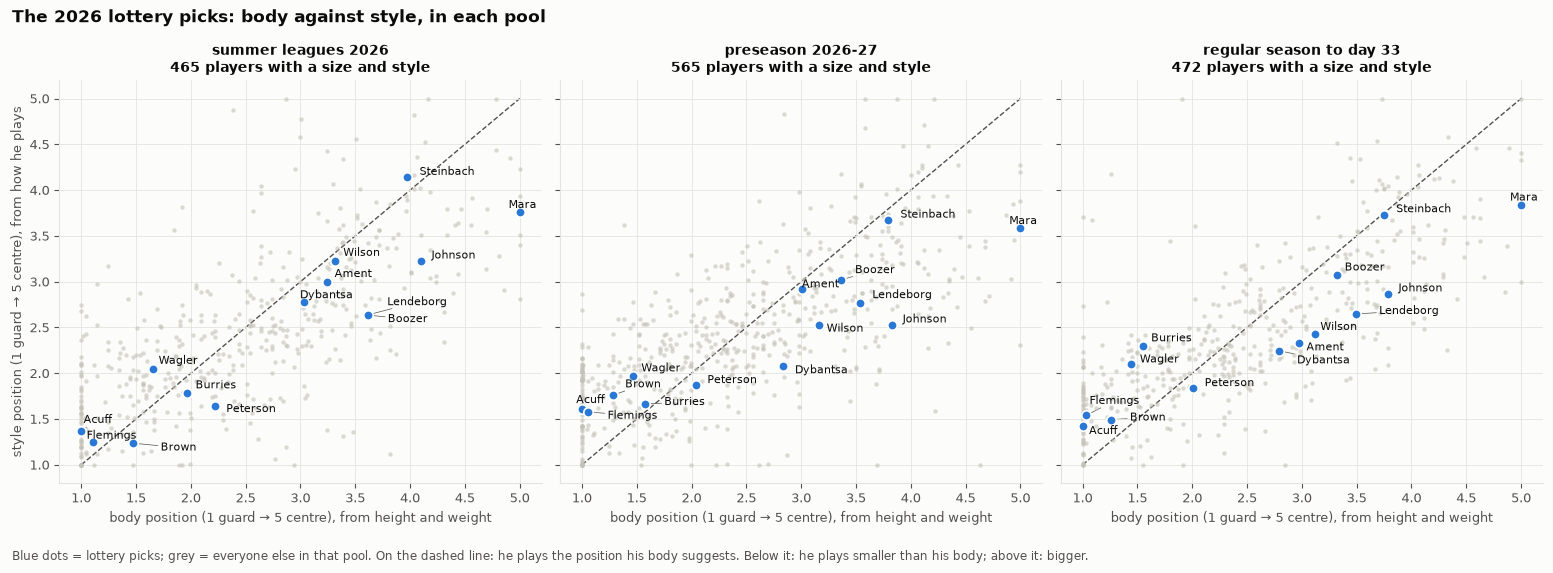

In [3]:
short26 = {pid: name.split()[-1] if name.split()[-1] not in ("Jr.",) else name.split()[-2] for pid, name in LOT26.items()}
fig = R.plot_maps(P26, short26, "The 2026 lottery picks: body against style, in each pool", FIG_DIR / "5_map_2026.png")

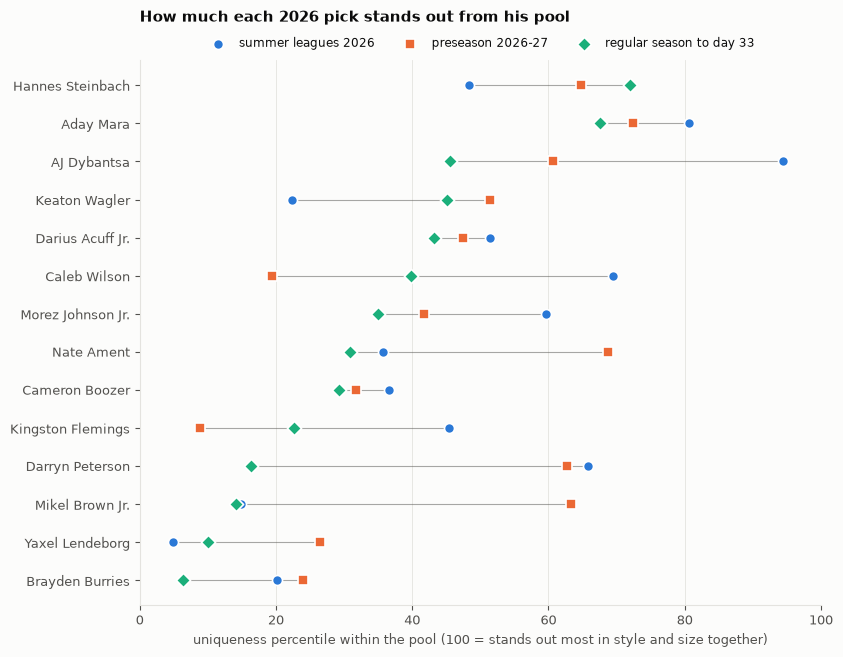

In [4]:
T26 = pick_table(P26, LOT26)
U26 = T26.pivot(index="player", columns="pool", values="uniqueness")[list(P26)]
fig = R.plot_uniqueness(U26, list(P26), "How much each 2026 pick stands out from his pool", FIG_DIR / "5_uniqueness_2026.png")

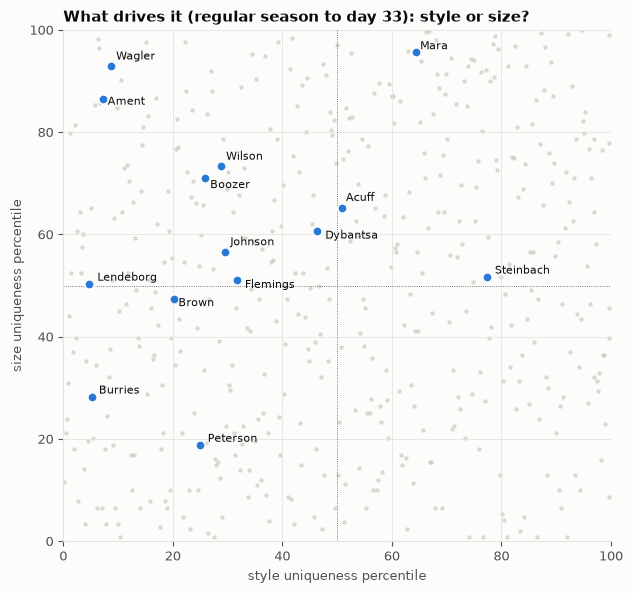

In [5]:
last26 = list(P26)[-1]
fig = R.plot_parts(P26[last26], short26, f"What drives it ({last26}): style or size?", FIG_DIR / "5_parts_2026.png")

In [6]:
display(T26.sort_values(["pool", "uniqueness"], ascending=[True, False]).set_index(["pool", "player"]))
for k, p in P26.items():
    top = p.sort_values("uniqueness_pctl", ascending=False).head(5)
    print(f"{k}, most unique of all: " + ", ".join(f"{r.player_name} ({r.min:.0f} min)" for r in top.itertuples()))

games  minutes  body position  style position  uniqueness  style part  size part  \
pool                     player                                                                                                
preseason 2026-27        Aday Mara              5      116            5.0             3.6        72.4        68.9       96.1   
                         Nate Ament             2       24            3.0             2.9        68.7        55.8       88.3   
                         Hannes Steinbach       4       60            3.8             3.7        64.7        73.5       53.8   
                         Mikel Brown Jr.        1       18            1.3             1.8        63.3        69.3       47.0   
                         Darryn Peterson        4       98            2.0             1.9        62.7        70.5       18.5   
                         AJ Dybantsa            4       86            2.8             2.1        60.6        57.6       65.3   
                         Keaton Wagler          3       81            1.5             2.0        51.4        26.9       94.6   
                         Darius Acuff Jr.       4       96            1.0             1.6        47.5        54.1       63.4   
                         Morez Johnson Jr.      2       26            3.8             2.5        41.7        33.2       57.2   
                         Cameron Boozer         4       81            3.4             3.0        31.8        38.3       71.4   
                         Yaxel Lendeborg        5      116            3.5             2.8        26.5        32.0       51.8   
                         Brayden Burries        4       92            1.6             1.7        23.9        37.1       28.4   
                         Caleb Wilson           5      133            3.2             2.5        19.4         7.2       74.4   
                         Kingston Flemings      5      112            1.1             1.6         8.8        10.4       51.0   
regular season to day 33 Hannes Steinbach       5       63            3.7             3.7        72.0        77.3       51.6   
                         Aday Mara             16      359            5.0             3.8        67.6        64.4       95.8   
                         AJ Dybantsa           14      474            2.8             2.2        45.6        46.4       60.7   
                         Keaton Wagler         15      332            1.4             2.1        45.1         8.7       92.9   
                         Darius Acuff Jr.      16      589            1.0             1.4        43.2        50.8       65.3   
                         Caleb Wilson          10      307            3.1             2.4        39.8        28.8       73.3   
                         Morez Johnson Jr.     16      277            3.8             2.9        35.0        29.4       56.6   
                         Nate Ament            15      277            3.0             2.3        30.9         7.2       86.4   
                         Cameron Boozer        16      492            3.3             3.1        29.2        25.8       71.1   
                         Kingston Flemings     13      285            1.0             1.5        22.7        31.8       51.1   
                         Darryn Peterson       18      546            2.0             1.8        16.3        25.0       18.8   
                         Mikel Brown Jr.       11      252            1.3             1.5        14.2        20.1       47.5   
                         Yaxel Lendeborg       17      539            3.5             2.6        10.0         4.7       50.2   
                         Brayden Burries       17      386            1.5             2.3         6.4         5.3       28.2   
summer leagues 2026      AJ Dybantsa            2       50            3.0             2.8        94.4        94.2       51.3   
                         Aday Mara              5      119            5.0   

summer leagues 2026, most unique of all: Josiah Allick (4 min), Devin McGlockton (3 min), Orlando Thomas (8 min), Robbie Avila (2 min), Dajuan Harris (6 min)
preseason 2026-27, most unique of all: Christian Koloko (4 min), Jalon Moore (6 min), Cameron Matthews (2 min), Alondes Williams (3 min), DeAndre Jordan (4 min)
regular season to day 33, most unique of all: Rocco Zikarsky (2 min), Carson Cooper (23 min), Zeke Nnaji (8 min), Lawson Lovering (2 min), Maliq Brown (1 min)


### Stage 1 findings (24 November 2026; regular season to 22 November, day 33)

Descriptive: 14 players, three pools, no minimum minutes yet (D59). Uniqueness is a percentile within each pool.

- **Aday Mara stands out in every pool** (68th to 81st percentile). Size is most of it: he is 7-3 and 255 lb (96th percentile on size). His style stands out too: blocks high (+2.0 SD in the regular season) and almost no threes (−1.7 SD). On the map his body says centre (5.0) but his style says 3.6–3.8: he plays smaller than his body.
- **Hannes Steinbach is the most unique pick in the regular season** (72nd), on style, not size: rim shots high (+2.3 SD), threes low (−1.8 SD), offensive boards high in the preseason. **Caution:** only 63 regular-season minutes.
- **AJ Dybantsa stood out most in summer league and has settled since:** 94th in summer league (usage +3.5 SD, mid-range +2.6 SD, but in only 50 minutes), 61st in the preseason, 46th in the regular season (474 minutes). His body says 2.8, his style 2.2: a forward's frame used more like a wing.
- **Darryn Peterson moved the most the other way:** 66th in summer league (usage +3.0 SD, assists +1.8 SD) and 63rd in the preseason, but 16th in the regular season. Self-created makes are still high (+1.5 SD); the rest of his profile is ordinary for a guard.
- **Keaton Wagler and Nate Ament stand out on size, not style** (size 86th–93rd, style 7th–9th in the regular season). Wagler is 6-6 and 175 lb: very light for his height (weight −1.8 SD).
- **The most typical picks:** Yaxel Lendeborg and Brayden Burries are below the 30th percentile in every pool.
- **The bigger picks play smaller than their bodies; the guards sit on or above the line.** In the regular season Mara, Morez Johnson Jr., Lendeborg, Dybantsa, Wilson and Ament are below the dashed line (style 0.6 to 1.2 positions smaller than body). Burries, Wagler, Acuff, Flemings and Brown are above it, partly because a body position cannot go below 1.
- **The most unique players overall are tiny samples** (2 to 23 regular-season minutes), as expected without a minimum minutes (D59). Minimum minutes are on the revisit list.

## Stage 1.1 — The 2015 lottery (Towns and Booker's class)

The same method for the 2015 lottery, at the three regular-season check-ins of 2015-16 (D63): the same day after opening night as Stage 1's snapshot, the All-Star break, and season's end. Plus the 2015-16 preseason.

**The 2015 summer leagues are dropped** (D61): NBA.com's 2015 summer-league dashboards have no player names, and their IDs match no other table, so shot zones, usage and the other team-context measures cannot be tied to a player. Rebuilding them was declined: no assumptions. It is on the revisit list.

In [7]:
LOT15 = lottery(2015)
g15 = load_game_logs(["2015-16"])
OPENING_15 = g15["game_date"].min()
cuts15 = {f"day {DAY} (start)": OPENING_15 + pd.Timedelta(days=DAY),
          "All-Star break": pd.Timestamp(all_star_breaks(g15).iloc[0]["last_game_before"]),
          "season's end": g15["game_date"].max()}
print(f"2015-16 opened {OPENING_15:%d %b %Y}; check-ins: " + ", ".join(f"{k} {v:%d %b %Y}" for k, v in cuts15.items()))

bio15 = R._bio(season="2015-16", season_type_all_star="Regular Season")
P15 = {"preseason 2015-16": scored(R.attach_sizes(R.preseason_pool("2015-16"),
                                                  R._bio(season="2015-16", season_type_all_star="Pre Season"), 2015), 2014)}
for k, cut in cuts15.items():
    P15[k] = scored(R.attach_sizes(R.regular_pool("2015-16", through=cut), bio15, 2015), 2014)
for k, p in P15.items():
    print(f"{k}: {len(p)} players; {int(p['height_in'].isna().sum())} without a size; "
          f"{int(p['position_style'].isna().sum())} without a style position; lottery picks: {int(p.index.isin(LOT15).sum())} of 14")

2015-16 opened 27 Oct 2015; check-ins: day 33 (start) 29 Nov 2015, All-Star break 11 Feb 2016, season's end 13 Apr 2016


preseason 2015-16: 548 players; 9 without a size; 0 without a style position; lottery picks: 14 of 14
day 33 (start): 423 players; 0 without a size; 0 without a style position; lottery picks: 14 of 14
All-Star break: 455 players; 0 without a size; 0 without a style position; lottery picks: 14 of 14
season's end: 476 players; 0 without a size; 0 without a style position; lottery picks: 14 of 14


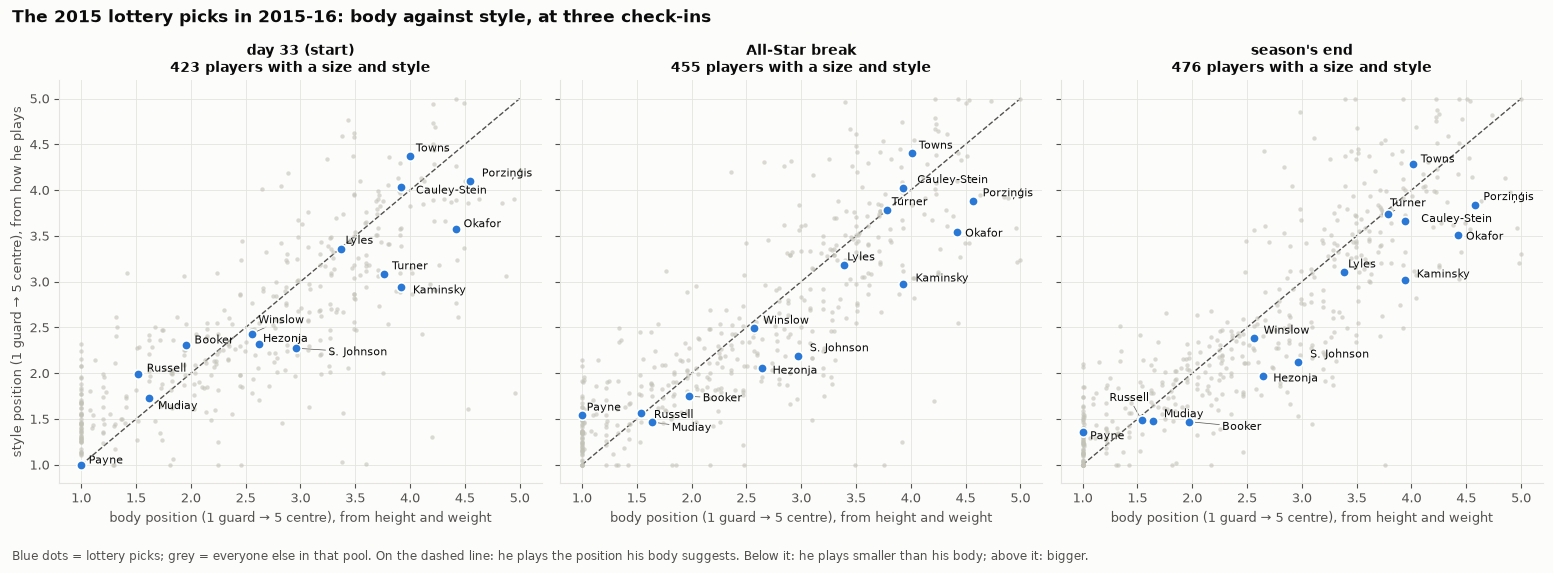

In [8]:
short15 = {pid: name.split()[-1] for pid, name in LOT15.items()}
short15 = {**short15, 1626156: "Russell", 1626169: "S. Johnson"}
fig = R.plot_maps({k: P15[k] for k in list(P15)[1:]}, short15, "The 2015 lottery picks in 2015-16: body against style, at three check-ins",
                  FIG_DIR / "5_map_2015.png")

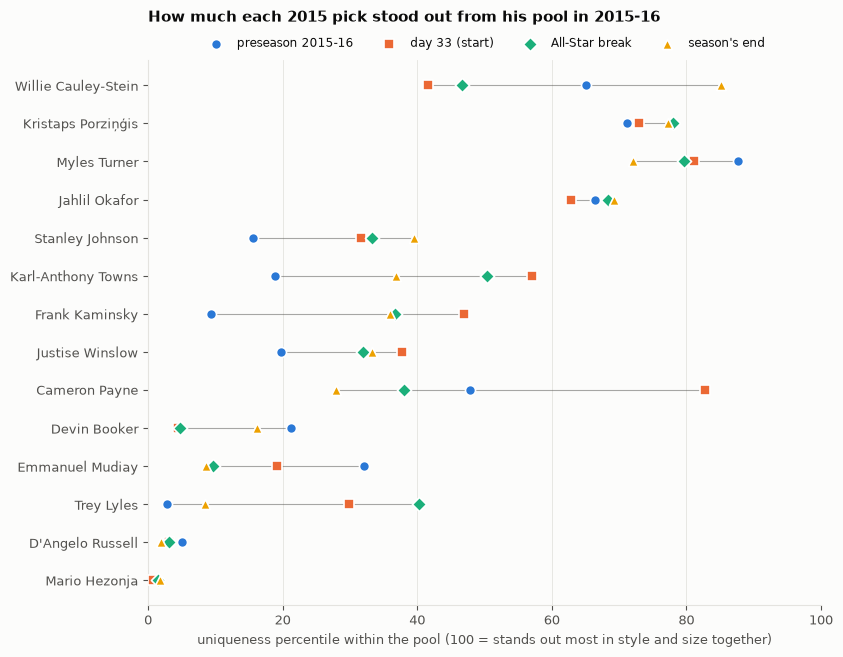

In [9]:
T15 = pick_table(P15, LOT15)
U15 = T15.pivot(index="player", columns="pool", values="uniqueness")[list(P15)]
fig = R.plot_uniqueness(U15, list(P15), "How much each 2015 pick stood out from his pool in 2015-16", FIG_DIR / "5_uniqueness_2015.png")

games  minutes  body position  style position  uniqueness  style part  size part  \
pool              player                                                                                                  
All-Star break    Myles Turner            31      628            3.8             3.8        79.6        83.1       43.3   
                  Kristaps Porziņģis      54     1524            4.6             3.9        78.0        62.0       98.5   
                  Jahlil Okafor           47     1434            4.4             3.5        68.4        52.7       93.5   
                  Karl-Anthony Towns      54     1624            4.0             4.4        50.3        53.6       69.0   
                  Willie Cauley-Stein     39      796            3.9             4.0        46.6        48.8       75.2   
                  Trey Lyles              50      856            3.4             3.2        40.2        48.1       29.0   
                  Cameron Payne           37      452            1.0             1.5        38.0        43.7       61.9   
                  Frank Kaminsky          52     1121            3.9             3.0        36.7         9.7       75.2   
                  Stanley Johnson         54     1293            3.0             2.2        33.2        13.2       76.7   
                  Justise Winslow         50     1393            2.6             2.5        31.9        43.1        3.7   
                  Emmanuel Mudiay         40     1209            1.6             1.5         9.7        15.2       24.8   
                  Devin Booker            48     1118            2.0             1.7         4.8        10.3       16.6   
                  D'Angelo Russell        53     1432            1.5             1.6         3.1         4.2       41.0   
                  Mario Hezonja           49      746            2.6             2.1         1.5         1.1       16.0   
day 33 (start)    Cameron Payne            8       32            1.0             1.0        82.7        84.4       63.5   
                  Myles Turner             8      126            3.8             3.1        81.1        84.9       41.6   
                  Kristaps Porziņģis      18      504            4.5             4.1        73.0        55.1       98.8   
                  Jahlil Okafor           18      595            4.4             3.6        62.9        51.3       94.2   
                  Karl-Anthony Towns      17      471            4.0             4.4        57.0        63.1       68.1   
                  Frank Kaminsky          16      234            3.9             2.9        47.0        29.6       73.6   
                  Willie Cauley-Stein     18      346            3.9             4.0        41.6        46.6       73.6   
                  Justise Winslow         15      433            2.6             2.4        37.8        47.5        3.5   
                  Stanley Johnson         17      351            3.0             2.3        31.7        14.7       78.5   
                  Trey Lyles              13      112            3.4             3.4        29.8        40.4       28.8   
                  Emmanuel Mudiay         17      512            1.6             1.7        19.1        26.5       27.0   
                  Devin Booker            13      156            2.0             2.3         4.5         8.0       17.6   
                  D'Angelo Russell        16      431            1.5             2.0         3.1         2.4       42.1   
                  Mario Hezonja           17      209            2.6             2.3         0.7         2.1       16.3   
preseason 2015-16 Myles Turner             6      102            3.8             4.4        87.6        88.5       45.6   
                  Kristaps Porziņģis       4       79            4.6             3.8        71.2        23.0       98.9   
                  Jahlil Okafor            5      104            4.4             3.5        66.4       

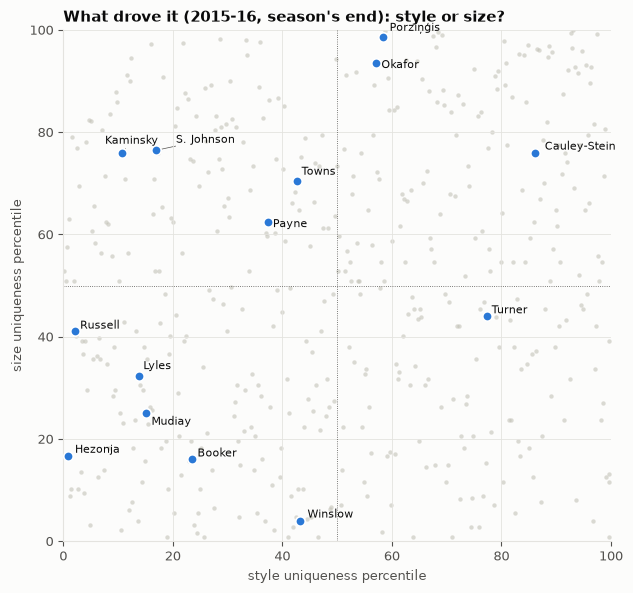

In [10]:
fig = R.plot_parts(P15["season's end"], short15, "What drove it (2015-16, season's end): style or size?", FIG_DIR / "5_parts_2015.png")
display(T15.sort_values(["pool", "uniqueness"], ascending=[True, False]).set_index(["pool", "player"]))

### How the 2015 picks' careers went

Descriptive only: 14 players are not a test. NBA seasons with any minutes from 2015-16 to 2025-26, total minutes, All-Star selections, and seasons in the star tier (the top 10% by star score; notebook 05).

In [11]:
from unicorn.established import load_star_tiers
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
asg = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "allstar_selections.parquet")
tiers = load_star_tiers()
rows = []
for pid, name in LOT15.items():
    c = ps[(ps["player_id"] == pid) & (ps["season_start"] >= 2015) & (ps["min"] > 0)]
    star = tiers[tiers.index.get_level_values(0) == pid]
    rows.append({"player": name, "pick": list(LOT15).index(pid) + 1, "NBA seasons": len(c), "career minutes": int(c["min"].sum()),
                 "All-Star selections": int((asg["player_id"] == pid).sum()),
                 "star-tier seasons": int(star[star.index.get_level_values(1) >= 2015].sum()),
                 "played 2025-26": bool((c["season_start"] == 2025).any())})
careers = pd.DataFrame(rows).set_index("player")
end = U15["season's end"].rename("uniqueness at 2015-16's end")
display(careers.join(end).sort_values("uniqueness at 2015-16's end", ascending=False))

,pick,NBA seasons,career minutes,All-Star selections,star-tier seasons,played 2025-26,uniqueness at 2015-16's end
player,,,,,,,
Willie Cauley-Stein,6,7,9274,0,0,False,85.1
Kristaps Porziņģis,4,10,16173,1,0,True,77.3
Myles Turner,11,11,20366,0,0,True,72.1
Jahlil Okafor,3,7,4829,0,0,False,69.3
Stanley Johnson,8,8,8877,0,0,False,39.5
Karl-Anthony Towns,1,11,24292,6,4,True,36.8
Frank Kaminsky,9,8,8159,0,0,False,35.9
Justise Winslow,10,8,8907,0,0,False,33.2
Cameron Payne,14,11,8730,0,0,True,27.9


### Stage 1.1 findings (24 November 2026)

Descriptive: 14 players, one season, no minimum minutes (D59). The 2015 summer leagues are dropped (D61).

- **The bigs stood out; the guards did not.** Kristaps Porziņģis (71st–78th), Myles Turner (72nd–88th) and Jahlil Okafor (63rd–69th) stood out at every check-in. Porziņģis on size (7-3) and blocks; Turner on mid-range for a big (+2.4 SD at season's end) and blocks; Okafor on usage and paint shots for his size. D'Angelo Russell, Mario Hezonja, Emmanuel Mudiay and Devin Booker were all below the 25th percentile from the start of the regular season on.
- **Percentiles still moved after the All-Star break:** Trey Lyles fell from 40th to 8th, Karl-Anthony Towns from 50th to 37th, Myles Turner from 80th to 72nd.
- **Caution, Willie Cauley-Stein:** he jumps from 47th at the break to 85th at season's end on "corner threes high (+3.5 SD)". He took **2 threes all season, both from the corner**, so his corner share is 100%. Six players in that pool have the same pattern (1 to 3 threes, all from the corner). This is D59's "as played" rule working as written, but corner share is fragile with so few attempts. On the revisit list.
- **Standing out early is not the same as lasting.** The two picks who became All-Stars several times were among the most ordinary in 2015-16: Devin Booker (5 selections; 16th percentile at season's end, 5th at the break) and Karl-Anthony Towns (6 selections; 37th at season's end). Of the four picks who stood out most, Porziņģis (1 selection) and Turner (11 seasons) lasted; Okafor (7 seasons, 4,829 minutes) and Cauley-Stein (7 seasons) did not. Fourteen players cannot test this; Stage 2 asks it across all seasons since 2000.

## Stage 2 — Play-style groups since 2000, reinvention and career length

**Question:** how many players reinvented their game, and does reinventing go hand in hand with a longer career?

**Set-up** ([decision log](../../docs/DECISIONS.md)):
- **Rows are team stints** (D51): a player traded mid-season has one row per team. Stints with 500+ minutes, 2000-01 to 2025-26 (D64).
- **Style only**, the same 15 measures, each **relative to that season's league** (D64), so a change is a change of role, not the league drifting to threes.
- **Seven groups** (D65), chosen by looking at fit and stability, and **named after they were found** (D66).
- **Reinvention** (D52): firmly (85%+) in one group, then firmly in another. Stints below 85% are "between groups".
- **Distance travelled** (D68): the **average step** between consecutive stints (main), the **sum of the steps**, and the **net distance** from a player's first three seasons to his latest three (6+ seasons only, so the two never overlap).
- **Career length** (D65): seasons played, for debuts from 2000-01. Careers still going are flagged, not projected.
- **Association only** (D53): longer careers have more stints, so more chances to change. Measures that grow with career length say so.

9175 team stints with 500+ minutes, 1635 players, 2000-01 to 2025-26; 81% firmly in one group (85%+)


,stability (soft mixture),stability (k-means),separation,fit (BIC),firm (85%+)
clusters,,,,,
2,0.928,0.950,0.248,342661.124,0.968
3,0.904,0.912,0.177,326765.992,0.915
4,0.716,0.866,0.136,319295.158,0.873
5,0.672,0.839,0.126,313772.918,0.850
6,0.622,0.751,0.101,309238.925,0.806
7,0.591,0.659,0.078,303827.555,0.805
8,0.541,0.596,0.059,301776.543,0.768
9,0.475,0.599,0.060,299790.858,0.761
10,0.463,0.542,0.058,298091.516,0.736


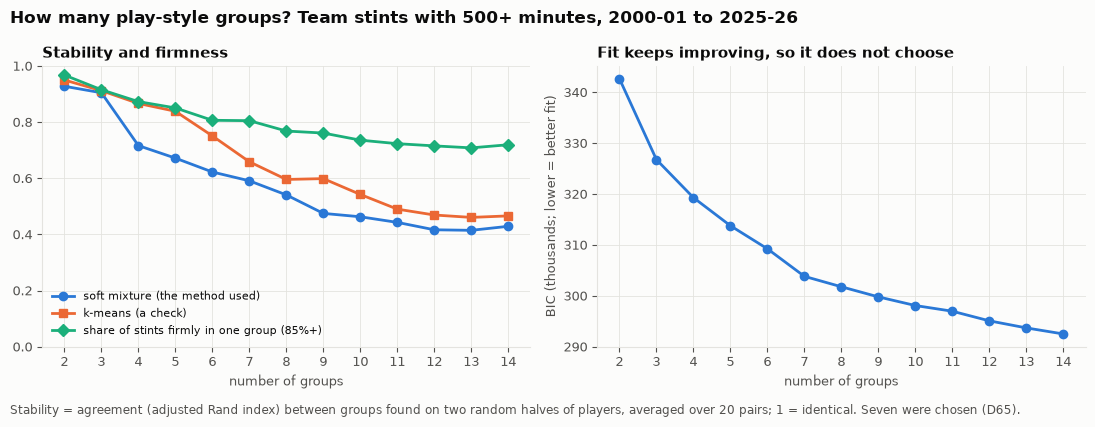

In [12]:
ST, X2, PC2, TYP2, KNOWN2 = R.stage2_groups()
print(f"{len(ST)} team stints with 500+ minutes, {ST['player_id'].nunique()} players, 2000-01 to 2025-26; "
      f"{(ST['state'] != 'between').mean():.0%} firmly in one group (85%+)")
SWEEP = R.group_sweep(ST)
display(SWEEP.round(3))
fig = R.plot_sweep(SWEEP, FIG_DIR / "5_how_many_groups.png")

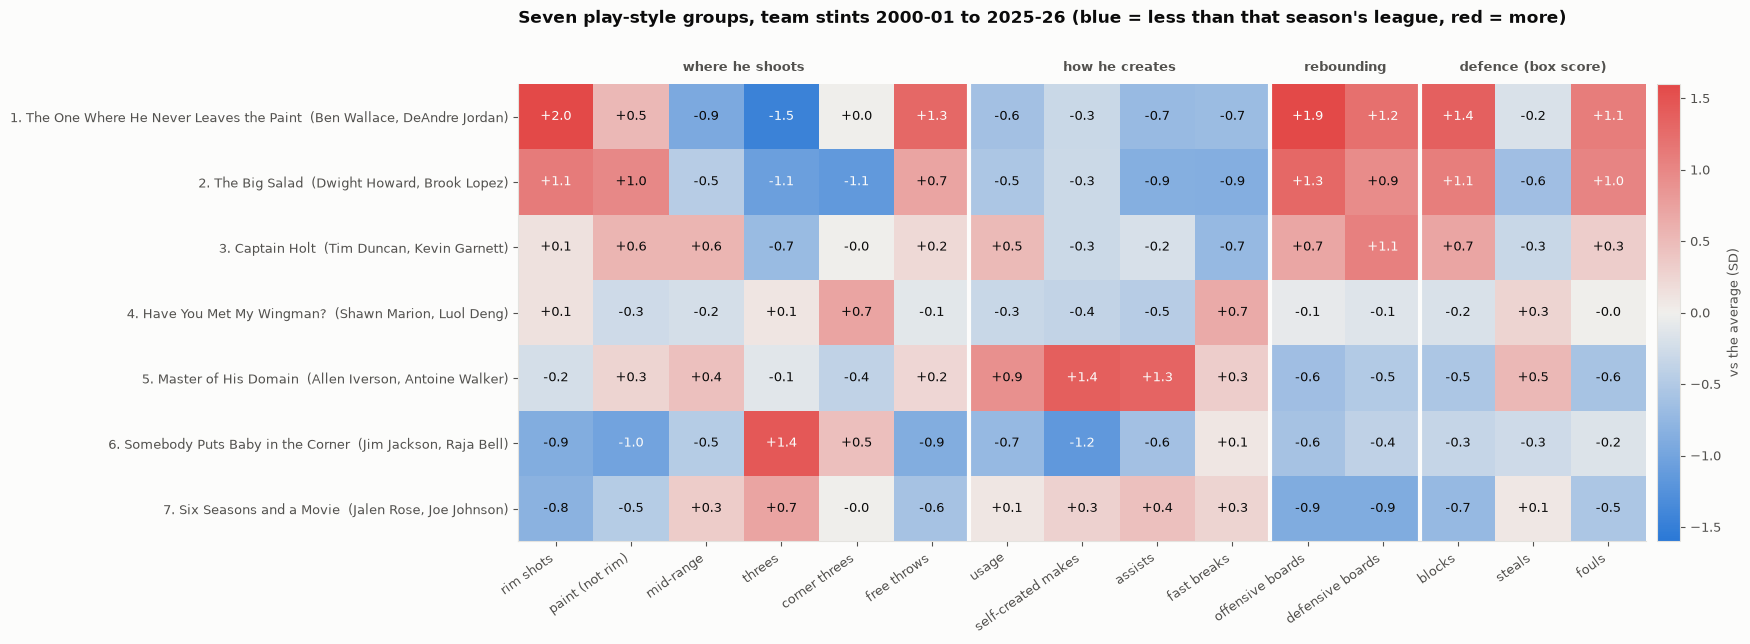

In [13]:
from unicorn.archetypes import FEATURES, profile_heatmap, who_is_in_which
prof2 = ST.groupby("group")[[f"{c}_z" for c in FEATURES]].mean(); prof2.columns = FEATURES
sizes2 = ST.groupby("group")[["height_in", "weight_lb"]].median().rename(columns={"height_in": "height", "weight_lb": "weight"})
known2, typical2 = KNOWN2, TYP2
when2 = lambda r: f"{r['season_start']}-{str(r['season_start'] + 1)[-2:]}, {r['team']}"
fig = profile_heatmap(prof2, known2, "5_seven_groups_profile.png",
                      "Seven play-style groups, team stints 2000-01 to 2025-26 (blue = less than that season's league, red = more)", names=R.GROUP_NAMES)

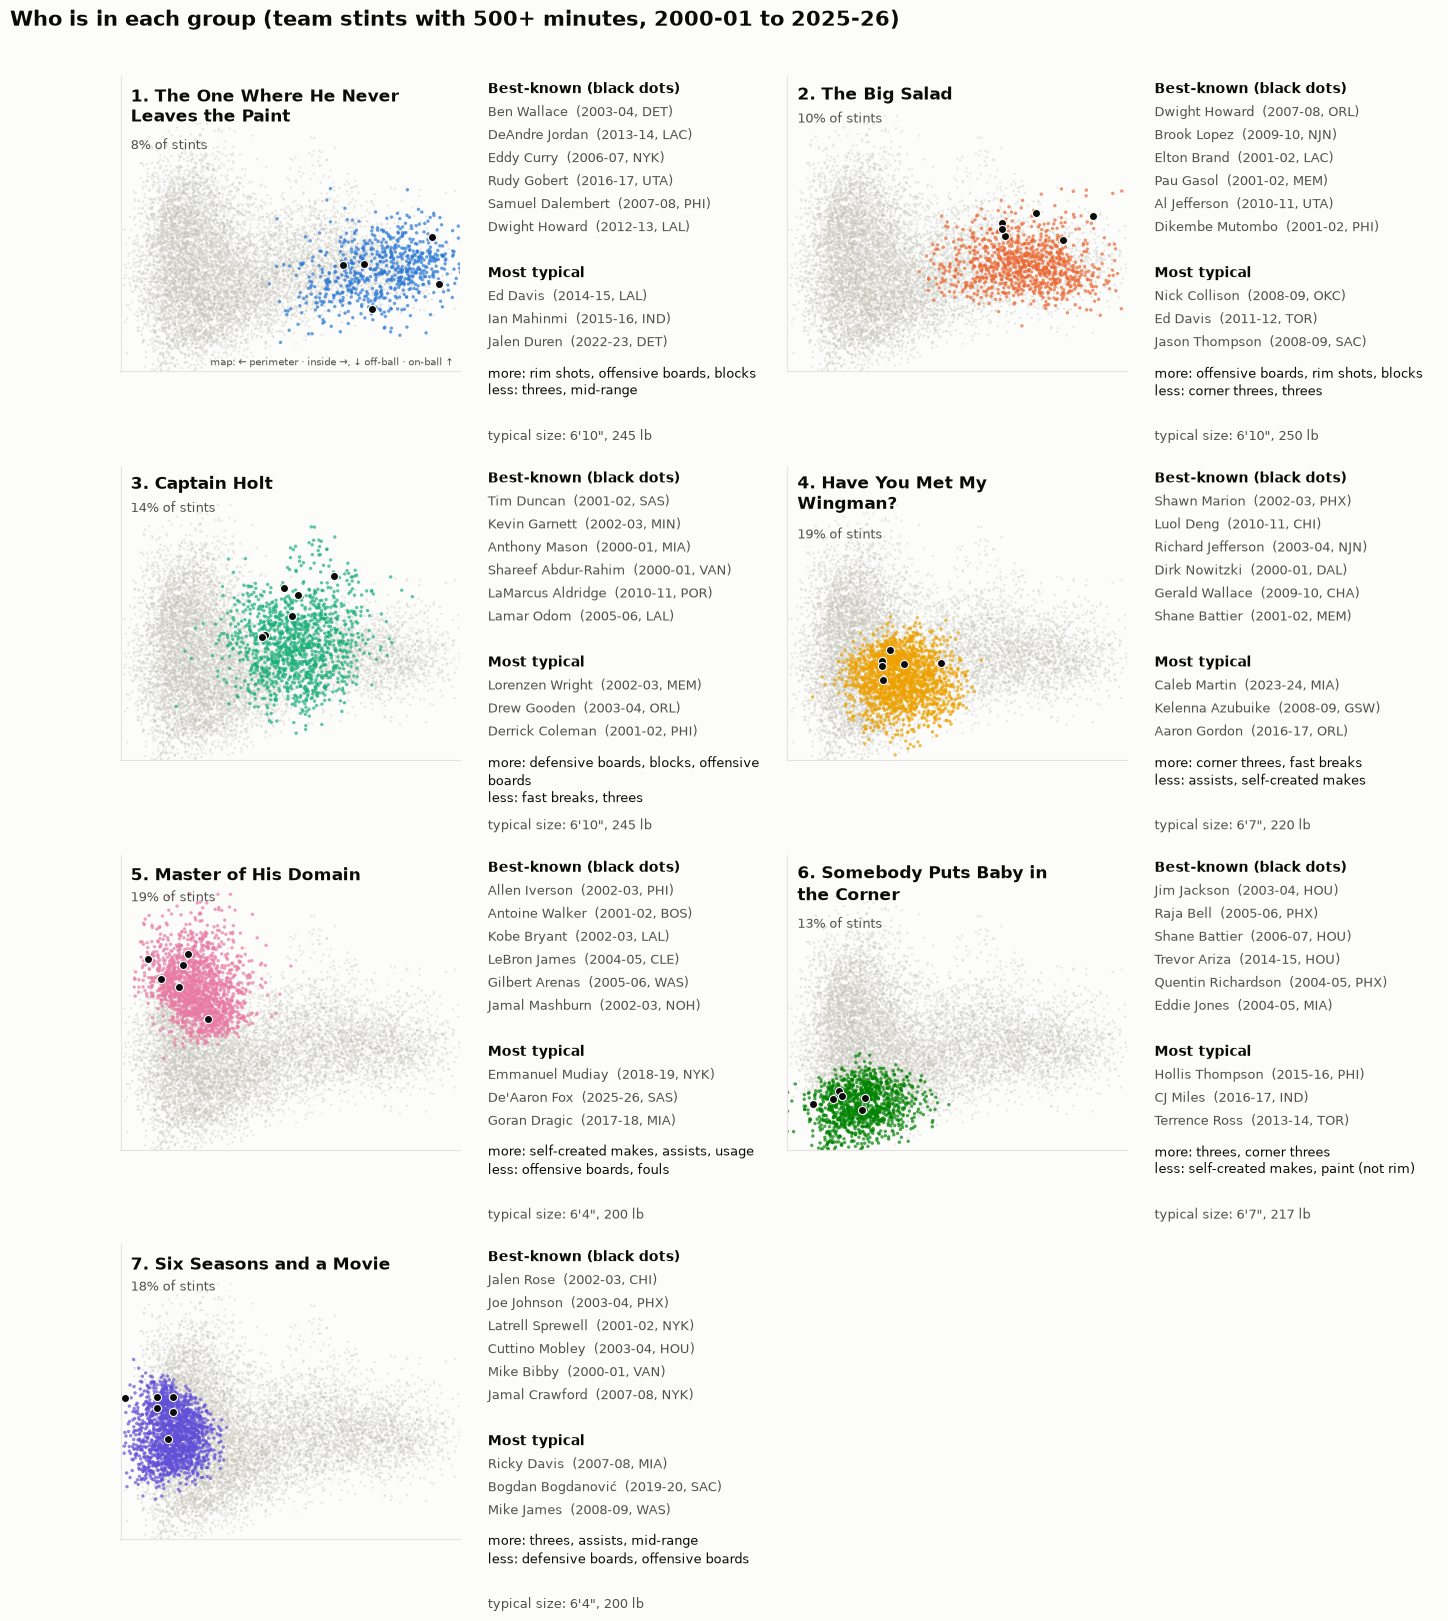

In [14]:
fig = who_is_in_which(PC2, ST["group"].to_numpy(), ST, known2, typical2, prof2, sizes2, when2, "5_seven_groups_who.png",
                      "Who is in each group (team stints with 500+ minutes, 2000-01 to 2025-26)", names=R.GROUP_NAMES, unit="stints")

### The plan's checks: Korver, Durant, LeBron, and two bigs who moved

Each player's path through the groups, stint by stint (group number, or "between"), with his three distance measures.

In [15]:
CAR = R.careers(ST)
checks = ["Kyle Korver", "Kevin Durant", "LeBron James", "Dwight Howard", "Brook Lopez", "Shane Battier"]
t = CAR[CAR["player_name"].isin(checks)].set_index("player_name").loc[checks]
display(t[["seasons_played", "group_changes", "average_step", "total_path", "net_distance", "path"]].round(2))
print("groups:", "; ".join(f"{k} {v}" for k, v in R.GROUP_NAMES.items()))

,seasons_played,group_changes,average_step,total_path,net_distance,path
player_name,,,,,,
Kyle Korver,17,0.0,1.66,29.85,1.72,6 > 6 > 6 > between > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6 > 6
Kevin Durant,18,4.0,1.47,24.99,3.13,5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 3 > 3 > 5 > between > 5 > 3 > between > between > 5
LeBron James,23,0.0,1.38,30.27,2.17,5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5 > 5
Dwight Howard,18,1.0,2.71,43.43,4.65,2 > 2 > 2 > 2 > 2 > 2 > 2 > 2 > 1 > 1 > between > 1 > 1 > 1 > 1 > 1 > 1
Brook Lopez,18,1.0,2.37,35.49,4.17,2 > 2 > 2 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3 > 3
Shane Battier,13,3.0,1.90,24.75,3.34,4 > between > 4 > 4 > 4 > 6 > 6 > 6 > 6 > 6 > 4 > 6 > 6 > 6


groups: 1 The One Where He Never Leaves the Paint; 2 The Big Salad; 3 Captain Holt; 4 Have You Met My Wingman?; 5 Master of His Domain; 6 Somebody Puts Baby in the Corner; 7 Six Seasons and a Movie


### Does reinventing go hand in hand with a longer career?

Rank correlation (Spearman) of each measure with seasons played, for players who debuted in 2000-01 or later.

,players,rank correlation with seasons played,note
measure,,,
group changes,1049,0.50,"partly built in: more stints, more chances"
total path,1049,0.90,mostly built in: grows with every stint
average step,1049,-0.14,main measure (D68)
net distance,537,0.44,6+ seasons only (D68)


,players,median_seasons,still_active
band,,,
least travelled,135,9.0,0.36
2nd,134,10.0,0.35
3rd,134,11.0,0.27
most travelled,134,12.0,0.37


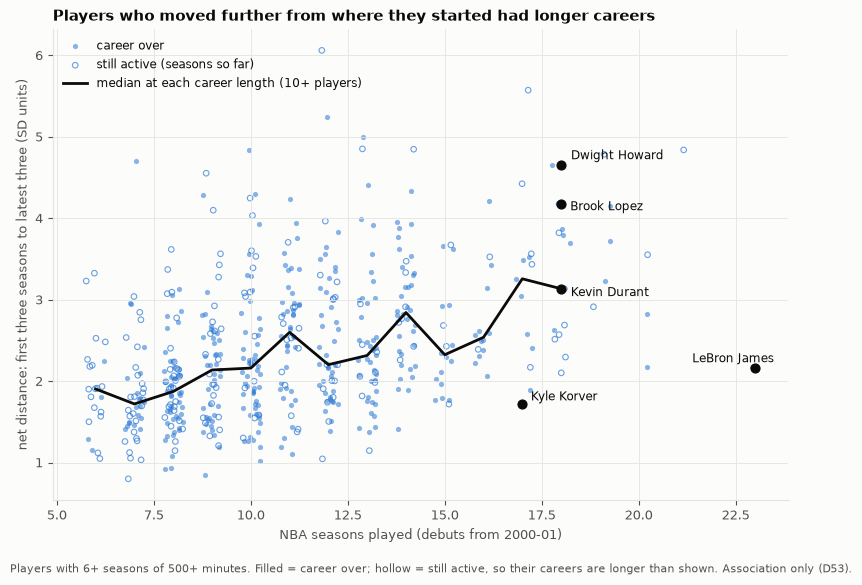

In [16]:
from scipy.stats import spearmanr
m = CAR[CAR["average_step"].notna()]
rows = []
for col, note in [("group_changes", "partly built in: more stints, more chances"), ("total_path", "mostly built in: grows with every stint"),
                  ("average_step", "main measure (D68)"), ("net_distance", "6+ seasons only (D68)")]:
    x = m.dropna(subset=[col])
    rows.append({"measure": col.replace("_", " "), "players": len(x), "rank correlation with seasons played": round(spearmanr(x[col], x["seasons_played"]).statistic, 2), "note": note})
display(pd.DataFrame(rows).set_index("measure"))
n6 = CAR[CAR["net_distance"].notna()].assign(band=lambda d: pd.qcut(d["net_distance"], 4, labels=["least travelled", "2nd", "3rd", "most travelled"]))
display(n6.groupby("band", observed=True).agg(players=("seasons_played", "size"), median_seasons=("seasons_played", "median"),
                                               still_active=("active", "mean")).round(2))
fig = R.plot_net_vs_career(CAR, ["Kyle Korver", "LeBron James", "Kevin Durant", "Dwight Howard", "Brook Lopez", "Steve Novak"],
                           FIG_DIR / "5_net_distance_career.png")

### Is a large step real adaptation or measurement wobble? (D69, D70)

A player's numbers wobble from one stretch of games to the next even if his role is unchanged, and more so over fewer minutes. Two tests, each with its rule written first:
- **D69:** steps after a team change against steps on the same team, at similar minutes. Rule: adaptation is supported if the new-team median is larger in every minutes band.
- **D70:** each step minus the wobble expected for its minutes, averaged per player, against seasons played. Rule: below −0.05 the link stands; −0.05 to +0.05 it was mostly wobble; above +0.05 it reverses.

In [17]:
STEPS = R.steps(ST)
t69 = STEPS.groupby(["band", "kind"], observed=True)["step"].agg(["size", "median"]).unstack("kind")
t69[("median", "new minus same")] = t69[("median", "new team")] - t69[("median", "same team")]
display(t69.round(2))
ok = (t69[("median", "new team")] > t69[("median", "same team")])
print(f"D69: new team larger in {int(ok.sum())} of {len(ok)} bands ->", "supported" if ok.all() else ("mixed" if ok.any() else "not supported"))
ex = CAR.join(STEPS.groupby("player_id")["extra"].mean().rename("average_extra"), how="inner")
r70 = spearmanr(ex["average_extra"], ex["seasons_played"]).statistic
print(f"D70: average extra step vs seasons played, rank correlation {r70:.2f} ->",
      "the link stands" if r70 < -0.05 else ("mostly wobble" if r70 <= 0.05 else "the link reverses"))

size             median                         
kind        new team same team new team same team new minus same
band                                                            
500-999         1475      1519     2.32      2.07           0.25
1,000-1,499      533      1156     2.08      1.80           0.28
1,500-1,999      304      1107     1.91      1.64           0.28
2,000+           215      1231     1.97      1.51           0.46

D69: new team larger in 4 of 4 bands -> supported
D70: average extra step vs seasons played, rank correlation -0.00 -> mostly wobble


### Stage 2 findings (24 November 2026)

Association only (D53): no claim that changing causes a longer career, or the reverse.

- **Seven play-style groups** across 9,175 team stints (1,635 players, 2000-01 to 2025-26); 81% of stints sit firmly (85%+) in one group. Seven was chosen by looking (D65). Re-run here, with the rows in date order and so different random halves, the stability for seven is 0.59 against 0.62 in the first run, and it slopes gently down from four groups (0.72) rather than staying flat as D65 says; k-means agreement is 0.66. The choice stands.
- **The plan's checks:**
  - **Kyle Korver** never left *Somebody Puts Baby in the Corner* (19 stints, no group change): a pure shooter from day one, as the plan expected.
  - **Kevin Durant** was not a pure shooter from day one: he moved between *Master of His Domain* and *Captain Holt* four times.
  - **LeBron James** stayed in *Master of His Domain* in all 23 seasons, so group changes cannot see his adjustments. Distance travelled can: his net distance (2.17) is larger than Korver's (1.72), while his average step (1.38) is among the smallest. He changed slowly and in one direction.
  - **Dwight Howard** (*The Big Salad* to *The One Where He Never Leaves the Paint*; net 4.65) and **Brook Lopez** (*The Big Salad* to *Captain Holt*, as he moved out to the three-point line; net 4.17) are among the furthest travelled.
- **Reinventing goes hand in hand with a longer career.** Net distance, for players with 6+ seasons so the windows never overlap (537 players): rank correlation 0.44 with seasons played; median careers of 9, 10, 11 and 12 seasons from the least to the most travelled quarter. The share still active is about the same in each quarter (27% to 37%). Group changes give 0.50, but are partly built in (more stints, more chances), and the sum of steps (0.90) is mostly built in.
- **How big each step is, on its own, says nothing about career length.** The average step first looked negative (−0.14), but part of every step is measurement wobble, larger over fewer minutes. With the wobble for each step's minutes taken out, the link is 0.00 (D70: mostly wobble).
- **Moving team brings real change.** Players' styles changed more after a team change than on the same team, at every level of minutes (+0.25 to +0.46 SD; D69). The gap is largest for players with 2,000+ minutes, where wobble is smallest.
- **Left for later** (revisit list): falling stars; and a possible arch, seen after D70 and not tested, in which players who change least and most beyond wobble both have the shortest careers.

## Stage 3 — Which past rookies do this year's look like?

To come.